# Segment subject brain according to the MultiConn atlas

To use the MultiConn atlas, one must segment individual brains according to the parcellation used in [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The MultiConn's parcellation is a combination of the cortical parcellation from [Cammoun et al. 2012]() and the subcortical parcellation from [Battistella et al. 2016](https://link.springer.com/article/10.1007/s00429-016-1336-4).

In this evaluation, we first generate the cortical and subcortical parcellations, and then use the Parcellation class to combine both into the MultiConn's parcellation.

The following process can be run with `mindmap.prior.make_MultiConn(...)`

## Imports

In [1]:
import mindmap as mm
from pathlib import Path
import subprocess
import nibabel as nib
from mindmap.utils.mri import Parcellation
import pandas as pd
import ants

## Data

In [2]:
sub     = "sub-pat10"
scale   = 4

# configuration
config  = mm.io.read_config("../configurations/spike.yml")
mm_dir  = Path(config["MM_DIR"])
fs_dir  = Path(config["FS_DIR"])
fs_home = Path(config["FS_HOME"])

# files
mri         = fs_dir/sub/"mri"/"orig"/"001.mgz"
laus2018L   = f'/home/nino/Data/atlas/laus2018/lh.atlas-laus2018_desc-scale{scale}.annot'
laus2018R   = f'/home/nino/Data/atlas/laus2018/rh.atlas-laus2018_desc-scale{scale}.annot'
thal_atlas  = '/home/nino/Data/atlas/Thalamic_Nuclei/Thalamus_Nuclei-HCP-4DSPAMs.nii.gz'
thal_clut   = '/home/nino/Data/atlas/Thalamic_Nuclei/Thalamic_Nuclei-ColorLUT.txt'
mni_temp    = '/home/nino/Data/atlas/mni_icbm152_nlin_asym_09c_nifti/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii'

# parameters
margin = 2
thresh = 0.05

# load data
mri        = ants.image_read(str(mri))
ref_atlas  = ants.image_read(str(mni_temp))
thal_atlas = ants.image_read(str(thal_atlas))

## Segment according to the Lausanne 2018 parcellation

#### Segmentation using FreeSurfer (1 min 30 s)

In [3]:
print(f"\033[96mSegmenting subject {sub} according to the Lausanne 2018 atlas ...\033[0m")

# temporary files
annotL    = fs_dir/sub/"label"/"lh.my-atlas.annot" 
annotR    = fs_dir/sub/"label"/"rh.my-atlas.annot" 
dparc_fs  = fs_dir/sub/"mri"/"my-atlas_space-fs_dparc.nii.gz"
dparc_sub = fs_dir/sub/"mri"/"my-atlas_space-orig_dparc.nii.gz"

print(f"\033[96mRegistering surface-based segmentation ...\033[0m")
subprocess.run(
    [
        "mri_surf2surf",
        "--srcsubject", "fsaverage",
        "--trgsubject", sub,
        "--hemi", "lh",
        "--sval-annot", str(laus2018L),
        "--tval", str(annotL),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

subprocess.run(
    [
        "mri_surf2surf",
        "--srcsubject", "fsaverage",
        "--trgsubject", sub,
        "--hemi", "rh",
        "--sval-annot", str(laus2018R),
        "--tval", str(annotR),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

print(f"\033[96mExpanding surface-based segmentation to volumetric segmentation ...\033[0m")
subprocess.run(
    [
        "mri_aparc2aseg",
        "--s", sub,
        "--annot", "my-atlas",
        "--wmparc-dmax", str(margin),
        "--labelwm",
        "--hypo-as-wm",
        "--new-ribbon",
        "--o", str(dparc_fs),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

print(f"\033[96mRegistering to subject ...\033[0m")
subprocess.run(
    [
        "mri_vol2vol",
        "--mov", str(dparc_fs),
        "--targ", str(fs_dir/sub/"mri"/"rawavg.mgz"),
        "--regheader",
        "--o", str(dparc_sub),
        "--no-save-reg",
        "--interp", "nearest",
    ],
    stdout=subprocess.PIPE, 
    universal_newlines=True,
)

Segmenting subject sub-pat10 according to the Lausanne 2018 atlas ...
Registering surface-based segmentation ...
Expanding surface-based segmentation to volumetric segmentation ...
Registering to subject ...


CompletedProcess(args=['mri_vol2vol', '--mov', '/home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/my-atlas_space-fs_dparc.nii.gz', '--targ', '/home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/rawavg.mgz', '--regheader', '--o', '/home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/my-atlas_space-orig_dparc.nii.gz', '--no-save-reg', '--interp', 'nearest'], returncode=0, stdout='movvol /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/my-atlas_space-fs_dparc.nii.gz\ntargvol /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/rawavg.mgz\noutvol /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat10/mri/my-atlas_space-orig_dparc.nii.gz\ninvert 0\ntal    0\ntalres 2\nregheader 1\nnoresample 0\ninterp  nearest (0)\nprecision  float (3)\nGdiag_no  -1\nSynth      0\nSynthSeed  1729214918\n\

#### Create the Color Look-Up Table

The Lausanne 2018 atlas includes more cortical regions than those in the FreeSurfer color look-up table (LUT). To create an updated color LUT for our segmentation, we will do the following:

- **Retain Non-Cortical Regions**: Keep the non-cortical regions from the FreeSurfer color LUT.
- **Add New Cortical Regions**: Incorporate the new cortical regions from the Lausanne atlas, ensuring we follow the FreeSurfer indexing system.

**Indexing in FreeSurfer**: The FreeSurfer color LUT assigns indices as follows:
- **1000-1999**: Right cortical gray matter regions
- **2000-2999**: Left cortical gray matter regions
- **3000-3999**: Right cortical white matter regions
- **4000-4999**: Left cortical white matter regions

In contrast, the cortical regions in the annotation files are indexed from 1 to the total number of regions. <br>

**Maintaining Proper Indexing**: To ensure correct indexing in our color LUT, we will:
- Create separate entries for right and left gray and white matter.
- Add 1000 for right gray, 2000 for left gray, 3000 for right white, and 4000 for left white, respectively.

This structured approach will ensure that our color LUT accurately represents the cortical regions in the Lausanne atlas while maintaining compatibility with FreeSurfer's indexing system.



In [4]:
# load data
volume  = nib.load(dparc_sub)                                    # Volume
fs_clut = mm.io.read_clut(fs_home/"FreeSurferColorLUT.txt")     # FreeSurfer color LUT 
lh_clut = mm.io.read_clut(annotL)                               # Left annotation color LUT
rh_clut = mm.io.read_clut(annotR)                               # Right annotation color LUT 

# correct clut 
laus2018_clut = fs_clut[(fs_clut["#No."]<1000) | (fs_clut["#No."]>4999)]     # Keep non-cortical regions 

gm_lh_clut, wm_lh_clut = lh_clut.copy(), lh_clut.copy()
gm_rh_clut, wm_rh_clut = rh_clut.copy(), rh_clut.copy()

gm_lh_clut["#No."] += 1000          # 1000-1999 
gm_rh_clut["#No."] += 2000          # 2000-2999
wm_lh_clut["#No."] += 3000          # 3000-3999
wm_rh_clut["#No."] += 4000          # 4000-4999

laus2018_clut = pd.concat([laus2018_clut, gm_lh_clut, gm_rh_clut, wm_lh_clut, wm_lh_clut])
laus2018_clut = laus2018_clut.sort_values(by=["#No."])

#### Create the parcellation and fuse gray+white matter

In [5]:
laus2018 = Parcellation(volume, laus2018_clut)
laus2018.change_ids([(3001, 3999), (4001, 4999)], lambda x: x-2000)

#### Deleting temporary files

In [6]:
annotL.unlink()
annotR.unlink()
dparc_fs.unlink()
dparc_sub.unlink()

#### Visualization of the Lausanne 2018 parcellation

In [ ]:
image_laus = laus2018.get_image()   # (1 min)

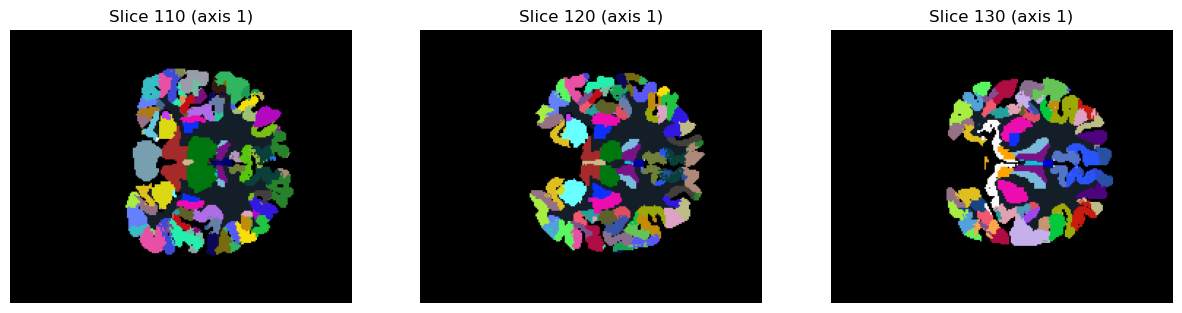

In [12]:
slices = [110, 120, 130]
mm.viz.show_slices(image_laus, slices, axis=1)

## Segmenting according to the Thalamic Nuclei atlas

In [7]:
# registration transform
mytx = ants.registration(
    fixed = ref_atlas,
    moving = mri,
    type_of_transform = "SyN",
)

# registration 
volume = ants.apply_transforms(
    fixed = mri,
    moving = thal_atlas,
    transformlist = mytx["invtransforms"],
    imagetype = 3,
    interpolator = "linear",
)

#### Create the parcellation and determinize it

In [8]:
volume = mm.utils.ants_to_nibabel(volume)
thal   = Parcellation(volume, thal_clut)
thal   = thal.prob2dseg(thresh=thresh)

#### Visualization of the thalamic nuclei parcellation

In [13]:
image_thal = thal.get_image()

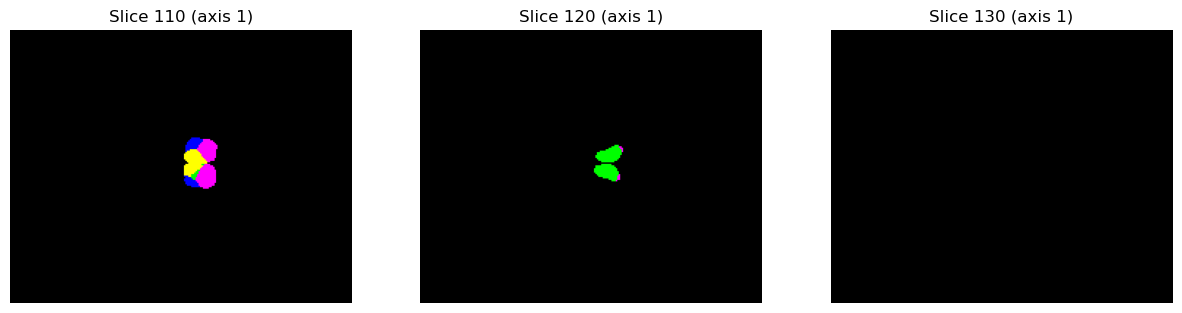

In [14]:
mm.viz.show_slices(image_thal, slices, axis=1)

## Fuse the Lausanne 2018 and Thalamic Parcellations
Run time: 1 min

In [15]:
# Extract and rename parts of interest from the Lausanne 2018 parcellation.
ctx_lh = laus2018.retain([(1001, 1999), (3001, 3999)])
ctx_lh.change_labels(prefix="ctx-lh-")

ctx_rh = laus2018.retain([(2001, 2999), (4001, 4999)])
ctx_rh.change_labels(prefix="ctx-rh-")

subc_lh = laus2018.retain([11, 12, 13, 26, 18, 17])
subc_lh.change_labels(replace={"Left-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-lh-", lower=True)

subc_rh = laus2018.retain([50, 51, 52, 58, 54, 53])
subc_rh.change_labels(replace={"Right-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-rh-", lower=True)

# Extract and rename parts of interest from the thalamic parcellation.
thal_lh = thal.retain([(8, 14)])

thal_rh = thal.retain([(1,7)])

brain_stem = laus2018.retain([16])
brain_stem.change_labels(replace={"-":"_"})

# join parts of interest
multi_conn = mm.utils.Parcellation()
multi_conn = multi_conn.join(ctx_rh)
multi_conn = multi_conn.join(thal_rh)
multi_conn = multi_conn.join(subc_rh)
multi_conn = multi_conn.join(ctx_lh)
multi_conn = multi_conn.join(thal_lh)
multi_conn = multi_conn.join(subc_lh)
multi_conn = multi_conn.join(brain_stem)

#### Visualize the MultiConn Parcellation

In [16]:
image_multiconn = multi_conn.get_image()

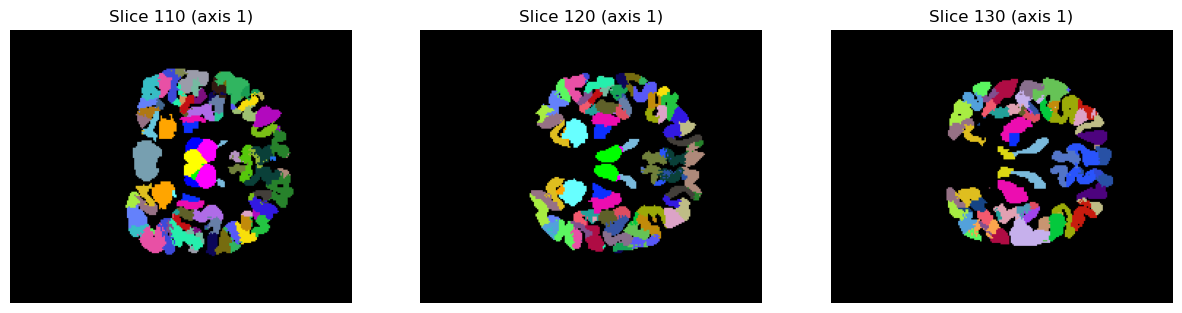

In [17]:
mm.viz.show_slices(image_multiconn, slices, axis=1)

## Saving parcellation

In [18]:
# save the parcellation
from pathlib import Path
import os

folder = mm_dir/sub/"parc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving MultiConn parcellation for subject: {sub}")
multi_conn.save(
    folder/f"{sub}_multiConn{scale}-{sub}-{thresh}_dparc.nii.gz",
    folder/f"{sub}_multiConn{scale}-{margin}-{thresh}_clut.txt",
)

Saving MultiConn parcellation for subject: sub-pat10


In [19]:
import pandas as pd

pd.set_option("display.max_rows", None)
multi_conn.get_clut()

,#No.,Label name,R,G,B,A
0,1,ctx-rh-lateralorbitofrontal_1,122,66,82,0.0
1,2,ctx-rh-lateralorbitofrontal_2,39,183,31,0.0
2,3,ctx-rh-lateralorbitofrontal_3,251,178,203,0.0
3,4,ctx-rh-lateralorbitofrontal_4,117,132,211,0.0
4,5,ctx-rh-lateralorbitofrontal_5,193,7,120,0.0
5,6,ctx-rh-lateralorbitofrontal_6,128,239,62,0.0
6,7,ctx-rh-lateralorbitofrontal_7,218,98,158,0.0
7,8,ctx-rh-parsorbitalis_1,209,251,121,0.0
8,9,ctx-rh-parsorbitalis_2,69,53,62,0.0
9,10,ctx-rh-frontalpole_1,134,248,137,0.0
